Importation des bibliothèques

In [228]:
from scipy.io.wavfile import read
import numpy as np
from numpy.fft import fft, fftshift, ifft, fftfreq
import matplotlib.pyplot as plt
import matplotlib
import scipy.signal as signal
import librosa
import librosa.display
import IPython.display as ipd
from sklearn import decomposition
FENETRE = 512
SAUT = 256

Téléchargement de l'audio

In [229]:
def chargement_audio(nom_fichier):
    rate = 5500
    son, rate = librosa.load("Fichiers_sonores/" + nom_fichier, sr = rate)
    return son, rate

Affichage du signal

In [230]:
def affichage_signal(son, rate):
       fig, ax = plt.subplots(figsize=(10, 3))
       librosa.display.waveshow(son, sr=rate, ax=ax,x_axis='time')
       ax.set(title='The sound waveform',
       xlabel='Time [s]')
       ax.legend()

Spectrogramme

In [231]:
def creation_spectrogramme(son_stft,afficher_specto,rate,SAUT):
    # Spectrogramme en amplitude
    son_stft_Magnitude = np.abs(son_stft)

    #Plot Spectogram
    spec = librosa.amplitude_to_db(son_stft_Magnitude, ref = np.max)
    librosa.display.specshow(spec,y_axis = 'hz',sr=rate,hop_length=SAUT,x_axis ='time',cmap= matplotlib.cm.jet)
    plt.title('Audio spectrogram')
    return son_stft_Magnitude, spec

In [232]:
def plot_spectrogram(frequencies, times, spectrogram, title="Spectrogram"):

    magnitude = np.abs(spectrogram)
    plt.figure(figsize=(10, 6))
    plt.pcolormesh(times, frequencies, 20 * np.log10(magnitude), shading='gouraud') #20 log de magnitude = pour mettre l'amplitude en dB
    plt.colorbar(label="Amplitude (dB)")
    plt.title(title)
    plt.xlabel("Temps (s)")
    plt.ylabel("Fréquence (Hz)")
    plt.show()


NMF

Initialisation

In [233]:
def init_NMF(son_stft_Magnitude):
    epsilon = 1e-10 # erreur 
    V = son_stft_Magnitude + epsilon
    return V

Fonction de la beta divergence

In [234]:
def divergence(V,W,H, beta ):
    
    """
    beta = 2 : Norme de Frobenius (erreur quadratique)
    beta = 1 : Divergence de Kullback-Leibler (KL) 
    beta = 0 : Divergence Itakura-Saito (IS)
    """ 
    
    if beta == 0 : return np.sum( V/(W@H) - np.log10(V/(W@H)) -1 )
    
    if beta == 1 : return np.sum( V*np.log10(V/(W@H)) + (W@H - V))
    
    if beta == 2 : return 1/2*np.linalg.norm(W@H-V)

In [235]:
def plot_NMF_iter(W, H,beta, rate , SAUT,iteration = None ):
    
    f = plt.figure(figsize=(4,4))
    f.suptitle(f"NMF Iteration {iteration}, for beta = {beta}", fontsize=8,)
    
    # definitions for the axes
    V_plot = plt.axes([0.35, 0.1, 1, 0.6])
    H_plot = plt.axes([0.35, 0.75, 1, 0.15])
    W_plot = plt.axes([0.1, 0.1, 0.2, 0.6])

    D = librosa.amplitude_to_db(W@H, ref = np.max)

    librosa.display.specshow(W,y_axis = 'hz', sr=rate, hop_length=SAUT,x_axis ='time',cmap= matplotlib.cm.jet, ax=W_plot)
    librosa.display.specshow(H,y_axis = 'hz', sr=rate, hop_length=SAUT,x_axis ='time',cmap= matplotlib.cm.jet, ax=H_plot)
    librosa.display.specshow(D,y_axis = 'hz', sr=rate, hop_length=SAUT,x_axis ='time',cmap= matplotlib.cm.jet, ax=V_plot)

    W_plot.set_title('Dictionnary W', fontsize=10)
    H_plot.set_title('Temporal activations H', fontsize=10)

    W_plot.axes.get_xaxis().set_visible(False)
    H_plot.axes.get_xaxis().set_visible(False)
    V_plot.axes.get_yaxis().set_visible(False)

Fonction NMF

In [236]:
def NMF(V, S, beta , afficher_specto,rate,SAUT, epsilon = 0.05, MAXITER = 5000, displayEveryNiter = None): 
    
    """
    inputs : 
    --------
    
        V         : Mixture signal : |TFST|
        S         : The number of sources to extract
        beta      : Beta divergence considered, default=2 (Euclidean)
        threshold : Stop criterion 
        MAXITER   : The number of maximum iterations, default=1000
        display   : Display plots during optimization : 
        displayEveryNiter : only display last iteration 
                                                            
    
    outputs :
    ---------
      
        W : dictionary matrix [KxS], W>=0
        H : activation matrix [SxN], H>=0
        cost_function : the optimised cost function over iterations
       
   Algorithm : 
   -----------
   
    1) Randomly initialize W and H matrices
    2) Multiplicative update of W and H 
    3) Repeat step (2) until convergence or after MAXITER 
    
       
    """
    compteur  = 0
    fonction_cout = []
    beta_divergence = 1
    
    K, N = np.shape(V)
    
    # On initialise de manière aléatoire W0 et H0 (l=0)
    W = np.abs(np.random.normal(loc=0, scale = 2.5, size=(K,S)))    
    H = np.abs(np.random.normal(loc=0, scale = 2.5, size=(S,N)))
    
    # Affichage de la première itération
    #plot_NMF_iter(W,H,beta,compteur)


    while beta_divergence >= epsilon and compteur <= MAXITER:
        
        # Mise à jour de W et H
        H *= (W.T@(((W@H)**(beta-2))*V))/(W.T@((W@H)**(beta-1)) + 10e-10) #on rajoute un epsilon pour ne jamais diviser par 0
        W *= (((W@H)**(beta-2)*V)@H.T)/((W@H)**(beta-1)@H.T + 10e-10)
        
        W = np.maximum(W, 1e-9) #on prend le max entre W et 1e-9 pour être sur de ne jamais prendre 0 0
        H = np.maximum(H, 1e-9)

        # Calcul de la fonction de coût
        beta_divergence =  divergence(V,W,H, beta)
        fonction_cout.append( beta_divergence )
        
        if compteur%displayEveryNiter == 0 and afficher_specto : 
            plot_NMF_iter(W,H,beta, rate=rate , SAUT=SAUT,iteration = compteur)

        compteur +=1
    
    if compteur -1 == MAXITER : print(f"On est arrivés à {MAXITER} itérations.")
    else : print(f" La fonction converge au bout de {counter-1} iterations.")
        
    return W,H, fonction_cout

Affichage de la fonction de cout

In [237]:
def affichage_cout(fonction_cout, beta):
    plt.figure(figsize=(5,3))
    plt.plot(fonction_cout)
    plt.title("Fonction de coût")
    plt.xlabel("Nombre d'itérations")
    plt.ylabel(f"Divergence bêta pour bêta = {beta} ")
 #On cherche à minimiser la fonction de coût, on voit clairement que le meilleur résultat  est obtenu pour beta = 2 (observation pour piano_mix)

Filtrage des sources

In [238]:
def filtrage_sources(W, H,V,S,afficher_spect,rate,SAUT):
    spectrogrammes_filtre = []
    if afficher_spect:
        f, axs = plt.subplots(nrows=1, ncols=S,figsize=(20,5))
    for i in range(S):
        
        # Filtrage de chaque source
        WsHs = W[:,[i]]@H[[i],:]
        spectrogramme_filtre = W[:,[i]]@H[[i],:] /(W@H *1e-9) * V 
        # Calculer le spectrogramme filtré
        D = librosa.amplitude_to_db(spectrogramme_filtre, ref = np.max)
        # Affichage du spectrogramme filtré
        if afficher_spect:
            axs[i].set_title(f"Frequency Mask of Audio Source s = {i+1}") 
            librosa.display.specshow(D,y_axis = 'hz', sr=rate,hop_length=SAUT,x_axis ='time',cmap= matplotlib.cm.jet, ax = axs[i])
        spectrogrammes_filtre.append(spectrogramme_filtre)
    return spectrogrammes_filtre

Reconstruction du signal

In [239]:
def reconstruction_signal(son_stft,spectrogrammes_filtre,S,FENETRE,SAUT):
    son_stft_angle = np.angle(son_stft)
    sons_reconstruits = []
    for i in range(S):
        fourier_inverse = spectrogrammes_filtre[i] * np.exp(1j*son_stft_angle)
        source_reconstruite   = librosa.istft(fourier_inverse, n_fft = FENETRE, hop_length = SAUT)
        sons_reconstruits.append(source_reconstruite)
    return sons_reconstruits

Affichage signaux reconstruits

In [ ]:
def affichage_signaux(S,sons_reconstruits,rate):
    fig, ax = plt.subplots(nrows=S, ncols=1, sharex=True, figsize=(10, 8))
    for i in range(S):
        librosa.display.waveshow(sons_reconstruits[i], sr=rate, ax=ax[i],label=f'Source {i}',axis='time')
        ax[i].set(xlabel='Temps [s]')
        ax[i].legend()
    

Ecoute des sources séparées

In [241]:
def ecoute_signaux_separes(S,sons_reconstruits,rate):
    for i in range(S):
        ipd.display(f"Source {i}",ipd.Audio(sons_reconstruits[i], rate=rate))

Protocole complet de séparation de sources audio

In [242]:
def protocole_complet(fichier,S,beta, afficher_spect,afficher_son,afficher_spect_son,afficher_cout) :
    #Chargement plus affichage audio
    son, rate = chargement_audio(fichier)
    affichage_signal(son, rate)

    #spectrogramme avec librosa
    FENETRE = 512
    SAUT = 256
    son_stft = librosa.stft(son, n_fft = FENETRE, hop_length = SAUT)
    son_stft_Magnitude, spec  = creation_spectrogramme(son_stft,afficher_specto=afficher_spect,rate=rate,SAUT=SAUT)

    #spectrogramme sans librosa
    #taille_fenetres = 1000
    #points_en_commun = 20
    #son_stft, t, spectrogramme = signal.stft(son, fs=rate, nperseg = taille_fenetres, noverlap = points_en_commun)
    #son_stft_Magnitude = np.abs(son_stft)
    #plot_spectrogram(son_stft, t, spectrogramme)

    #NMF
    V = init_NMF(son_stft_Magnitude)
    W, H, fonction_cout = NMF(V,S,beta = beta,afficher_specto= afficher_spect, rate=rate , SAUT= SAUT, epsilon = 0.05, MAXITER = 10000, displayEveryNiter = 5000)   
    if afficher_cout :
        affichage_cout(fonction_cout, beta)
    #Spectrogramme des sons filtrés et reconstruction des signaux
    spectrogrammes = filtrage_sources(W, H,V,S,afficher_spect, rate=rate , SAUT=SAUT)
    sons_separes = reconstruction_signal(son_stft,spectrogrammes,S,FENETRE=FENETRE , SAUT=SAUT)

    #Affichage et écoute des signaux séparés
    if afficher_spect_son:
        affichage_signaux(S,sons_separes,rate=rate)
    if afficher_son : 
        ecoute_signaux_separes(S,sons_separes,rate=rate)

piano


/tmp/ipykernel_14428/3993222471.py:3: FutureWarning: waveshow() keyword argument 'x_axis' has been renamed to 'axis' in version 0.10.0.
	This alias will be removed in version 1.0.
  librosa.display.waveshow(son, sr=rate, ax=ax,x_axis='time')
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


beta= 0
On est arrivés à 10000 itérations.


'Source 0'

'Source 1'

'Source 2'

...

/tmp/ipykernel_14428/3993222471.py:3: FutureWarning: waveshow() keyword argument 'x_axis' has been renamed to 'axis' in version 0.10.0.
	This alias will be removed in version 1.0.
  librosa.display.waveshow(son, sr=rate, ax=ax,x_axis='time')
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


beta= 2
On est arrivés à 10000 itérations.


'Source 0'

'Source 1'

'Source 2'

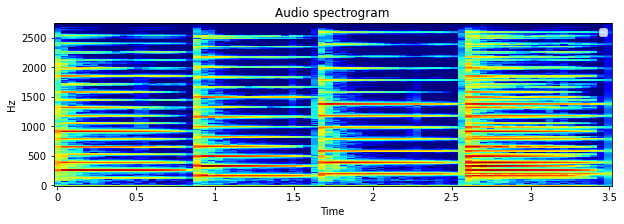

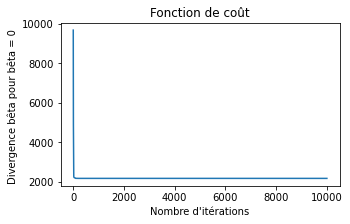

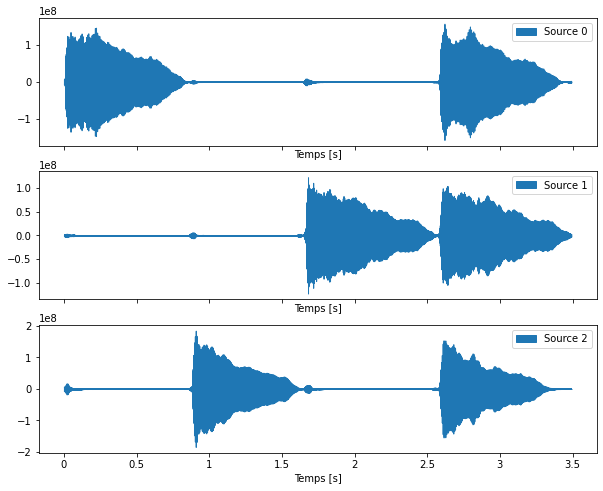

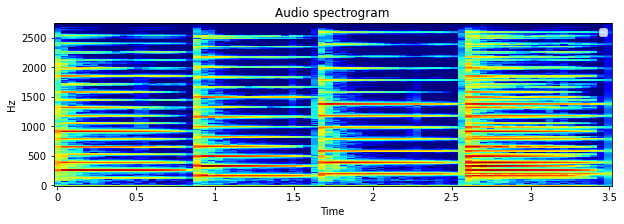

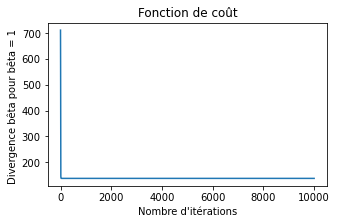

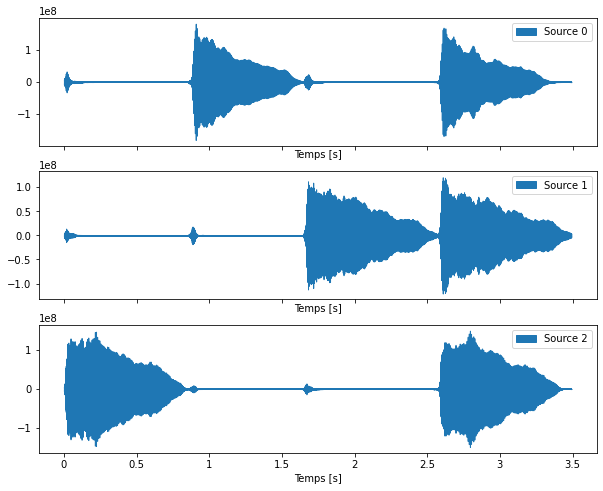

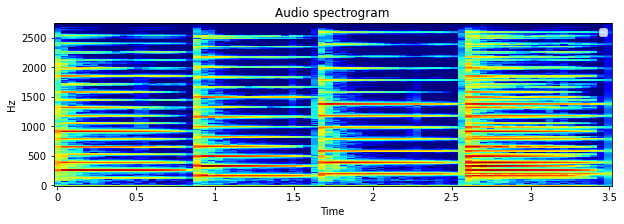

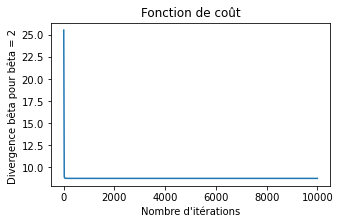

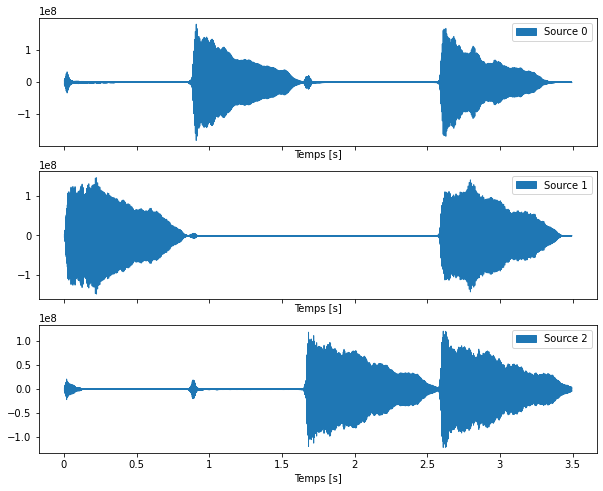

In [248]:
for i in range(3):
    print(f'beta= {i}')
    protocole_complet("piano_mix.wav",3,i, afficher_spect= False ,afficher_son =True ,afficher_spect_son =True , afficher_cout= True)
#on aime bien 0 et on est arrivé a 1000 itération donc on est pas assez proche

/tmp/ipykernel_14428/3993222471.py:3: FutureWarning: waveshow() keyword argument 'x_axis' has been renamed to 'axis' in version 0.10.0.
	This alias will be removed in version 1.0.
  librosa.display.waveshow(son, sr=rate, ax=ax,x_axis='time')
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


beta= 0
On est arrivés à 10000 itérations.


'Source 0'

'Source 1'

'Source 2'

...

/tmp/ipykernel_14428/3993222471.py:3: FutureWarning: waveshow() keyword argument 'x_axis' has been renamed to 'axis' in version 0.10.0.
	This alias will be removed in version 1.0.
  librosa.display.waveshow(son, sr=rate, ax=ax,x_axis='time')
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


beta= 2
On est arrivés à 10000 itérations.


'Source 0'

'Source 1'

'Source 2'

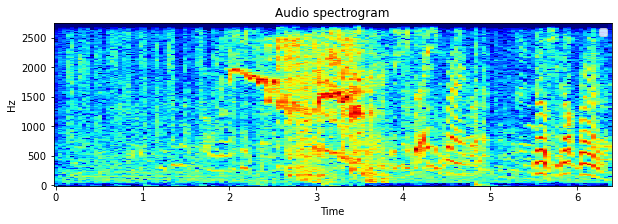

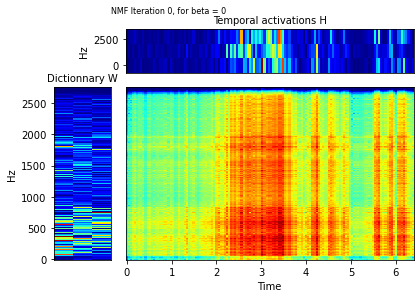

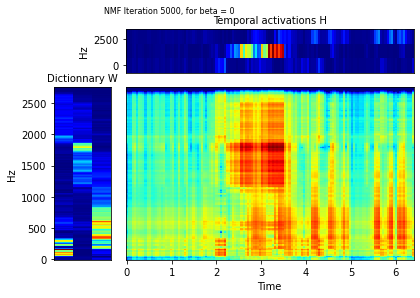

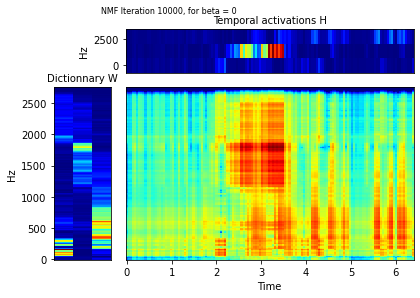

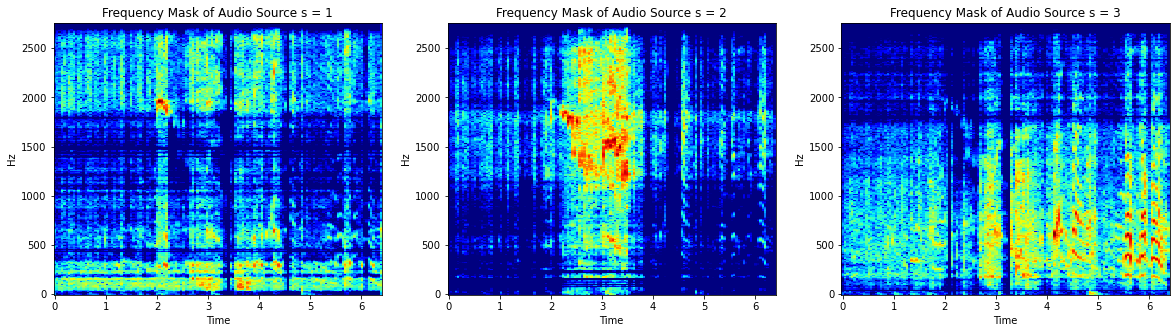

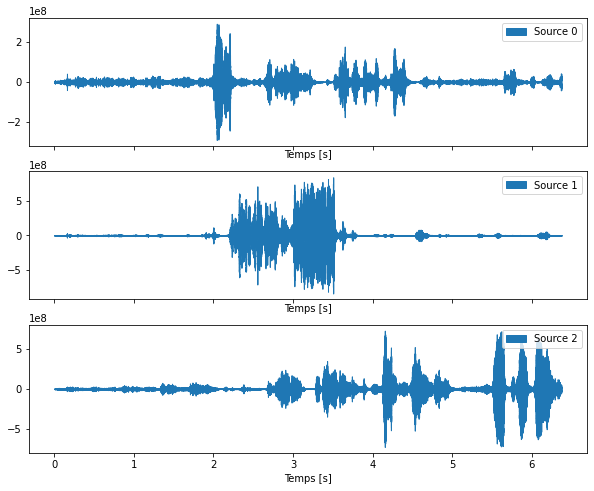

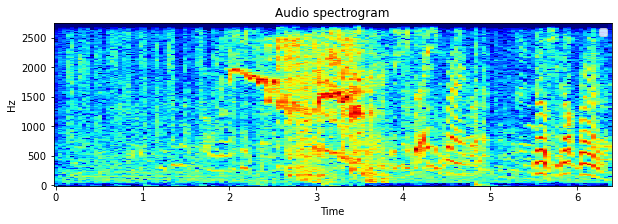

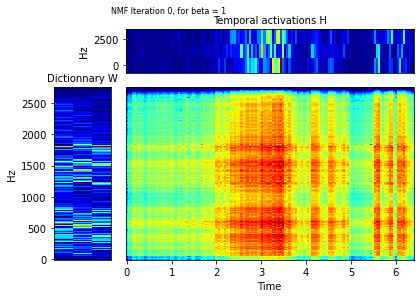

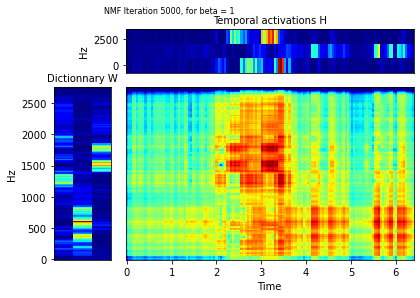

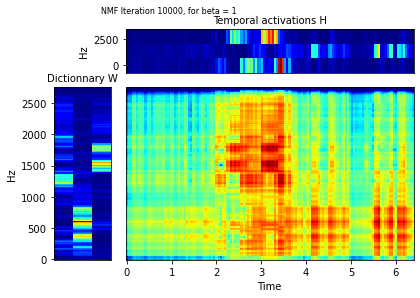

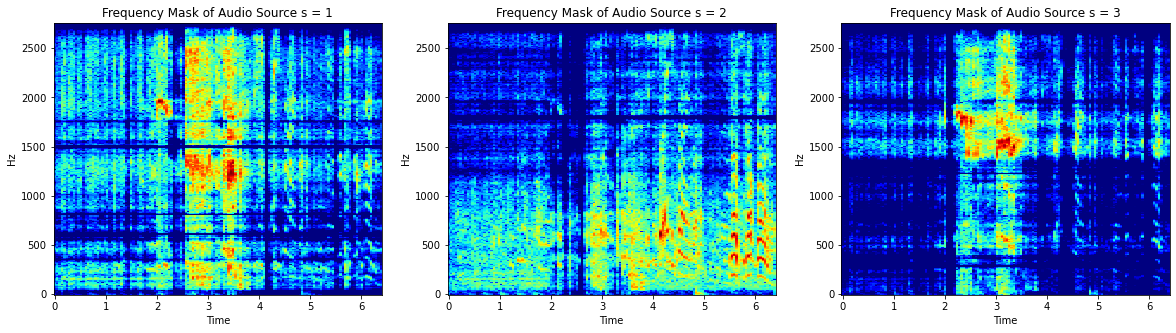

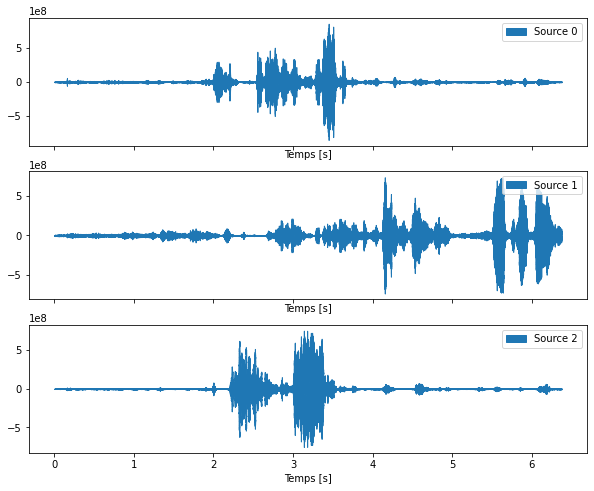

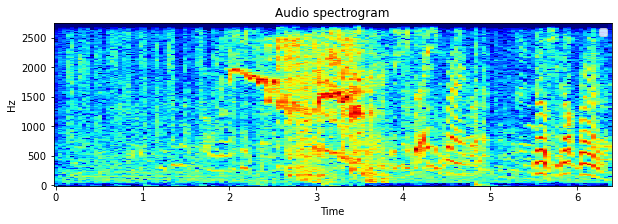

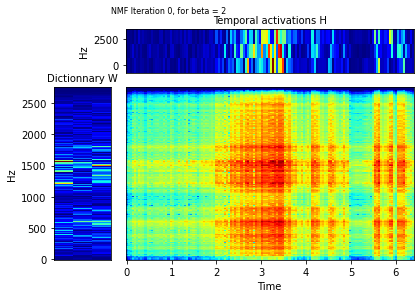

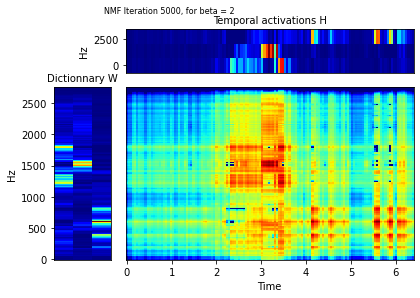

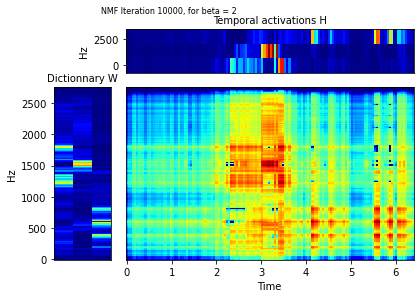

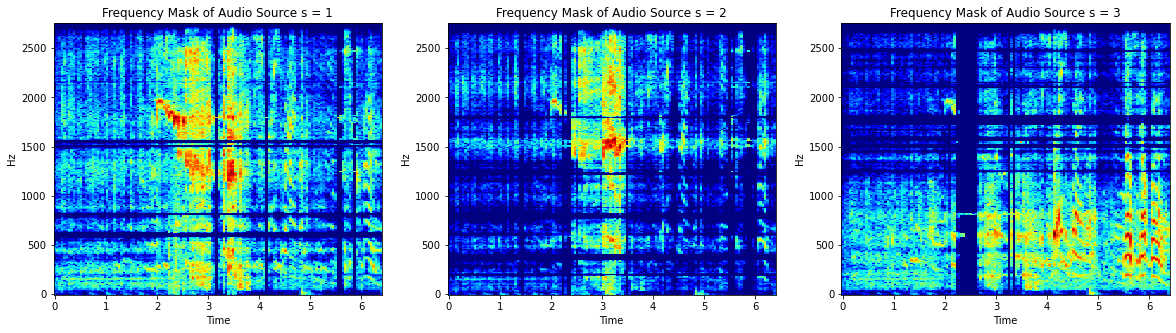

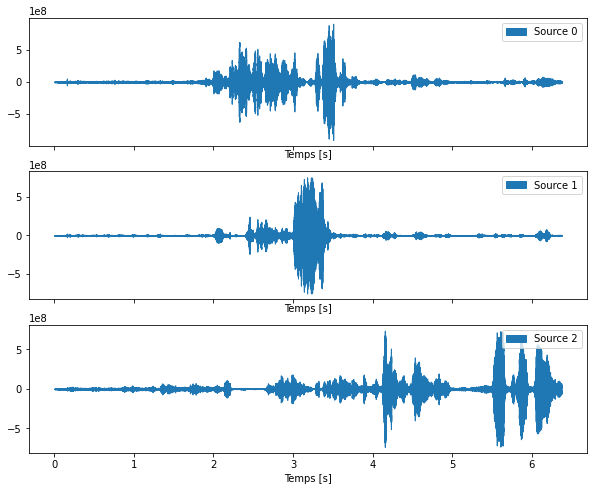

In [247]:
for i in range(3):
    print(f'beta= {i}')
    protocole_complet("horse_and_chat.wav",3,i, afficher_spect= True ,afficher_son =True ,afficher_spect_son =True , afficher_cout= False)
    #on aime bien 0 et un peu 2 et on est arrivé a 1000 itération donc on est pas assez proche

In [ ]:
for i in range(3):
    print(f'beta= {i}')
    protocole_complet("01-AchGottundHerr.wav",3,i, afficher_spect= False ,afficher_son =True ,afficher_spect_son =True , afficher_cout= False)

/tmp/ipykernel_14428/3993222471.py:3: FutureWarning: waveshow() keyword argument 'x_axis' has been renamed to 'axis' in version 0.10.0.
	This alias will be removed in version 1.0.
  librosa.display.waveshow(son, sr=rate, ax=ax,x_axis='time')
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


beta= 0
On est arrivés à 10000 itérations.


'Source 0'

'Source 1'

'Source 2'

/tmp/ipykernel_14428/3993222471.py:3: FutureWarning: waveshow() keyword argument 'x_axis' has been renamed to 'axis' in version 0.10.0.
	This alias will be removed in version 1.0.
  librosa.display.waveshow(son, sr=rate, ax=ax,x_axis='time')
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


beta= 1


NMF avec sklearn

In [ ]:
decomposition.NMF()
model=decomposition.NMF(n_components=3, init = 'random', random_state = 0)
W_sklearn = model.fit_transform(V)
H_sklearn = model.components_
plot_NMF_iter(W_sklearn,H_sklearn,'test')
#print(W_sklearn)
print(H_sklearn.shape)
print(W_sklearn.shape)

NameError: name 'V' is not defined

IndexError: index 3 is out of bounds for axis 1 with size 3

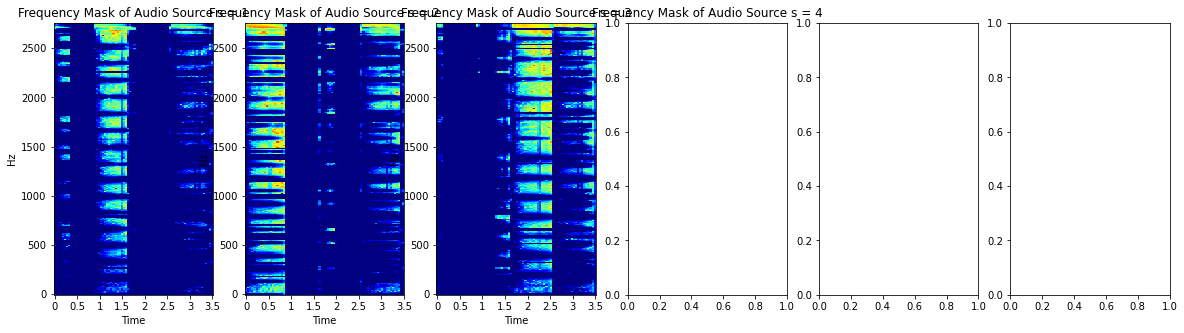

In [ ]:
f, axs = plt.subplots(nrows=1, ncols=S,figsize=(20,5))
spectrogrammes_filtre = []
for i in range(S):
    axs[i].set_title(f"Frequency Mask of Audio Source s = {i+1}") 
    # Filtrage de chaque source
    WsHs = W_sklearn[:,[i]]@H_sklearn[[i],:]
    spectrogramme_filtre = W_sklearn[:,[i]]@H_sklearn[[i],:] /((W_sklearn@H_sklearn) * V +10e-10)
    # Calculer le spectrogramme filtré
    D = librosa.amplitude_to_db(spectrogramme_filtre, ref = np.max)
    # Affichage du spectrogramme filtré
    librosa.display.specshow(D,y_axis = 'hz', sr=rate,hop_length=SAUT,x_axis ='time',cmap= matplotlib.cm.jet, ax = axs[i])
    
    spectrogrammes_filtre.append(spectrogramme_filtre)

In [ ]:
son_stft_angle = np.angle(son_stft)
sons_reconstruits = []
for i in range(S):
    fourier_inverse = spectrogrammes_filtre[i] * np.exp(1j*son_stft_angle)
    source_reconstruite   = librosa.istft(fourier_inverse, n_fft = FENETRE, hop_length = SAUT)
    sons_reconstruits.append(source_reconstruite)

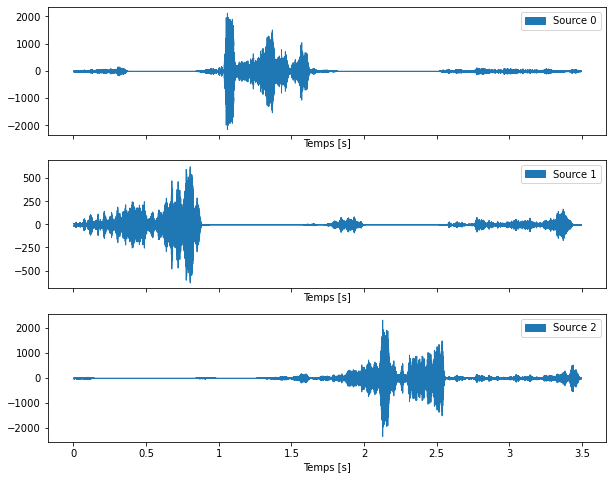

In [ ]:
fig, ax = plt.subplots(nrows=S, ncols=1, sharex=True, figsize=(10, 8))
for i in range(S):
    librosa.display.waveshow(sons_reconstruits[i], sr=rate, ax=ax[i],label=f'Source {i}',axis='time')
    ax[i].set(xlabel='Temps [s]')
    ax[i].legend()

In [ ]:
for i in range(S):
    ipd.display(f"Source {i}",ipd.Audio(sons_reconstruits[i], rate=rate))

'Source 0'

'Source 1'

'Source 2'